In [10]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Literal
from langchain_google_genai import ChatGoogleGenerativeAI
from dotenv import load_dotenv
from langchain_core.messages import SystemMessage, HumanMessage
from pydantic import BaseModel, Field

In [21]:
generator_llm=ChatGoogleGenerativeAI(model='gemini-3-flash-preview')
evaluator_llm=ChatGoogleGenerativeAI(model='gemini-3.5-flash')
optimizer_llm=ChatGoogleGenerativeAI(model='gemini-3.8-flash')


In [12]:
#define state
class PostState(TypedDict):
    topic: str
    text: str
    evaluation: Literal["approved", "needs_improvement"]
    feedback: str
    iteration: int
    max_iteration: int

In [13]:
class evaluationSchema(BaseModel):
    evaluation: Literal["approved", "needs_improvement"]=Field(description="final evaluation result")
    feedback: str=Field(description="constructive feedback on Post")

In [14]:
structured_evaluation_llm=evaluator_llm.with_structured_output(evaluationSchema)

In [15]:
#define node
def generate_node(state: PostState)->PostState:

    messages=[
        SystemMessage(content="You are a funny and technical linkedin influencer"),
        HumanMessage(content=f"""
        write a short, original, and technical post on the linkedin: "{state['topic']}".

        Rules:
        - Do NOT use question-answer format.
        - Max 200 characters.
        - Use observational humor, irony, sarcasm or technical references.
        - Think in meme logic, punchlines, or relatable takes.
        - Use simple, day to day english.
""")
    ]

    response=generator_llm.invoke(messages).content

    return {'text': response[0]['text']}

def evaluate_node(state: PostState)->PostState:
    post=state['text']

    prompt=f"""
            You are a professional LinkedIn content evaluator. Evaluate the following LLM-generated post based on clarity, relevance, originality, authenticity, grammar, professionalism, and engagement potential.

    1. Originality Is this fresh or have you seen it a hundered times before ?
    2. Humor- Did it genuinely make you smile, laugh or chuckle ? 
    3. Identify the key strengths and weaknesses.
    4. Highlight generic or robotic AI-generated language.
    5. Suggest specific improvements.
    6. Decide whether the post is approved or needs optimization.

    Be critical, concise, and objective. Preserve the original intent and never invent facts.

    **Post to evaluate:** \n
    {post}
"""

    response=structured_evaluation_llm.invoke(prompt)

    return {'evaluation': response.evaluation, 'feedback': response.feedback }

def optimizer_node(state: PostState):
    post=state['text']

    feedback=state['feedback']

    prompt=f'optimize the following post: \n {post} \n On the basis of given feedback \n {feedback}'

    response=optimizer_llm.invoke(prompt).content
    iteration=state['iteration'] + 1

    return {'text': response[0]['text'], 'iteration': iteration}

def route_evaluation(state: PostState)->Literal["optimizer_node", "__end__"]:

    if state['evaluation'] == "approved" or state['iteration'] >= state['max_iteration']:
        return END
    else:
        return "optimizer_node"


    

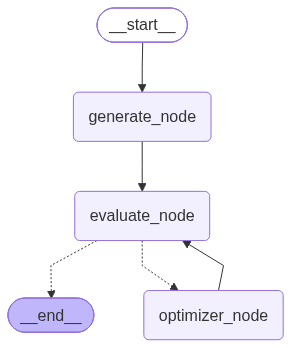

In [16]:
graph=StateGraph(PostState)

graph.add_node('generate_node', generate_node)
graph.add_node('evaluate_node', evaluate_node)
graph.add_node('optimizer_node', optimizer_node)
# graph.add_node('route_evaluation', route_evaluation)


graph.add_edge(START, 'generate_node')
graph.add_edge('generate_node', 'evaluate_node')
graph.add_conditional_edges('evaluate_node', route_evaluation)

graph.add_edge('optimizer_node', 'evaluate_node')

workflow=graph.compile()
workflow


In [22]:
initial_state={'topic': "create a linkedin post on Reverse Engineer Anything(REA)", 'iteration': 1, 'max_iteration': 5}
final_state=workflow.invoke(initial_state)

final_state

{'topic': 'create a linkedin post on Reverse Engineer Anything(REA)',
 'text': 'Reverse engineering is 20% decoding logic and 80% digital archaeology.\n\nStare at a decompiler long enough, and the human story surfaces. Past the stripped symbols and aggressive compiler optimizations, you inevitably hit an arbitrary hardcoded offset or a chaotic, 400-line nested switch case—the exact spot where someone abandoned architectural elegance just to survive the release cycle.\n\nTools like Ghidra and IDA give you the syntax, but the real differentiator is pattern recognition: figuring out not just *what* the machine instructions are doing, but *why* an engineer made that specific compromise under pressure.\n\nTo the RE community: What’s the most blatant "make it compile, ship it now" hack you’ve ever uncovered in disassembly?\n\n#ReverseEngineering #CyberSecurity #MalwareAnalysis #SecurityResearch',
 'evaluation': 'approved',
 'feedback': "Originality: The metaphor of reverse engineering as 'di